In [1]:

import numpy as np
import pandas as pd

# Reproducible random data
np.random.seed(42)

n = 1000

# Generate customer features
tenure = np.random.randint(1, 73, n)

monthly_charges = np.random.randint(500, 5001, n)

support_tickets = np.random.poisson(2, n)

late_payments = np.random.poisson(1, n)

# Create a probability of customer churn
logit = (
    -1.5
    - 0.035 * tenure
    + 0.00025 * monthly_charges
    + 0.45 * support_tickets
    + 0.55 * late_payments
)

churn_probability = 1 / (1 + np.exp(-logit))

# Generate binary target
churn = np.random.binomial(
    1,
    churn_probability
)

# Create DataFrame
df = pd.DataFrame({
    "tenure": tenure,
    "monthly_charges": monthly_charges,
    "support_tickets": support_tickets,
    "late_payments": late_payments,
    "churn": churn
})

print(df.head())
print("\nDataset shape:", df.shape)
print("\nChurn distribution:")
print(df["churn"].value_counts())


   tenure  monthly_charges  support_tickets  late_payments  churn
0      52             3962                3              2      0
1      15             3579                0              1      1
2      72             1332                3              1      0
3      61             4908                2              0      0
4      21             3306                3              0      0

Dataset shape: (1000, 5)

Churn distribution:
churn
0    625
1    375
Name: count, dtype: int64


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   tenure           1000 non-null   int32
 1   monthly_charges  1000 non-null   int32
 2   support_tickets  1000 non-null   int32
 3   late_payments    1000 non-null   int32
 4   churn            1000 non-null   int32
dtypes: int32(5)
memory usage: 19.7 KB


In [3]:
df.describe()

,tenure,monthly_charges,support_tickets,late_payments,churn
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.881000,2770.028000,2.007000,1.010000,0.375000
std,20.958915,1327.458541,1.399611,0.990394,0.484365
min,1.000000,501.000000,0.000000,0.000000,0.000000
25%,17.750000,1546.750000,1.000000,0.000000,0.000000
50%,35.500000,2807.500000,2.000000,1.000000,0.000000
75%,54.000000,3952.250000,3.000000,2.000000,1.000000
max,72.000000,4997.000000,9.000000,5.000000,1.000000


In [4]:
df.isnull().sum()

tenure             0
monthly_charges    0
support_tickets    0
late_payments      0
churn              0
dtype: int64

In [5]:
df["churn"].value_counts(normalize=True)

churn
0    0.625
1    0.375
Name: proportion, dtype: float64

In [6]:
X = df.drop("churn", axis=1)

y = df["churn"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   tenure  monthly_charges  support_tickets  late_payments
0      52             3962                3              2
1      15             3579                0              1
2      72             1332                3              1
3      61             4908                2              0
4      21             3306                3              0

Target:
0    0
1    1
2    0
3    0
4    0
Name: churn, dtype: int32


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [9]:
predictions = model.predict(X_test)

print(predictions[:20])

[0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0]


In [10]:
probabilities = model.predict_proba(X_test)

print(probabilities[:5])

[[0.64789023 0.35210977]
 [0.91868903 0.08131097]
 [0.38311864 0.61688136]
 [0.76077492 0.23922508]
 [0.6132894  0.3867106 ]]


In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Accuracy: 0.71

Confusion Matrix:
[[106  19]
 [ 39  36]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.85      0.79       125
           1       0.65      0.48      0.55        75

    accuracy                           0.71       200
   macro avg       0.69      0.66      0.67       200
weighted avg       0.70      0.71      0.70       200



In [12]:
### Lesson 2 - Statistical Analysis

In [13]:
print(df.describe())

            tenure  monthly_charges  support_tickets  late_payments  \
count  1000.000000      1000.000000      1000.000000    1000.000000   
mean     35.881000      2770.028000         2.007000       1.010000   
std      20.958915      1327.458541         1.399611       0.990394   
min       1.000000       501.000000         0.000000       0.000000   
25%      17.750000      1546.750000         1.000000       0.000000   
50%      35.500000      2807.500000         2.000000       1.000000   
75%      54.000000      3952.250000         3.000000       2.000000   
max      72.000000      4997.000000         9.000000       5.000000   

             churn  
count  1000.000000  
mean      0.375000  
std       0.484365  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       1.000000  
max       1.000000  


In [14]:
for column in df.columns:
    print(f"\nColumn: {column}")
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode().iloc[0])


Column: tenure
Mean: 35.881
Median: 35.5
Mode: 62

Column: monthly_charges
Mean: 2770.028
Median: 2807.5
Mode: 1161

Column: support_tickets
Mean: 2.007
Median: 2.0
Mode: 2

Column: late_payments
Mean: 1.01
Median: 1.0
Mode: 0

Column: churn
Mean: 0.375
Median: 0.0
Mode: 0


In [15]:
print(df.std(numeric_only=True))

tenure               20.958915
monthly_charges    1327.458541
support_tickets       1.399611
late_payments         0.990394
churn                 0.484365
dtype: float64


In [16]:
correlation = df.corr(numeric_only=True)

print(correlation)

                   tenure  monthly_charges  support_tickets  late_payments  \
tenure           1.000000         0.000634         0.000028      -0.042235   
monthly_charges  0.000634         1.000000        -0.017478       0.039784   
support_tickets  0.000028        -0.017478         1.000000      -0.015938   
late_payments   -0.042235         0.039784        -0.015938       1.000000   
churn           -0.251082         0.073643         0.224993       0.232142   

                    churn  
tenure          -0.251082  
monthly_charges  0.073643  
support_tickets  0.224993  
late_payments    0.232142  
churn            1.000000  


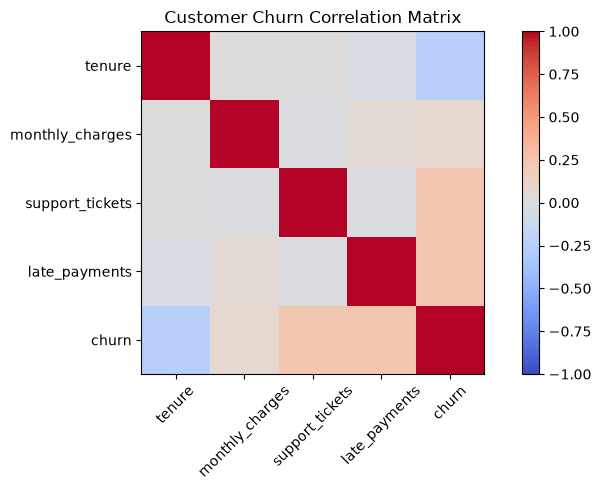

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Customer Churn Correlation Matrix")
plt.tight_layout()
plt.show()

In [18]:
Q1 = df["monthly_charges"].quantile(0.25)
Q3 = df["monthly_charges"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["monthly_charges"] < lower) |
    (df["monthly_charges"] > upper)
]

print("Potential outlier count:", len(outliers))
print(outliers.head())

Potential outlier count: 0
Empty DataFrame
Columns: [tenure, monthly_charges, support_tickets, late_payments, churn]
Index: []


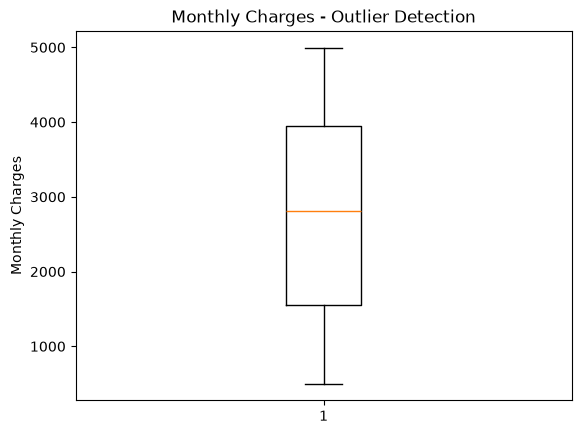

In [19]:
plt.boxplot(df["monthly_charges"])
plt.title("Monthly Charges - Outlier Detection")
plt.ylabel("Monthly Charges")
plt.show()

In [20]:
test_data = df.copy()

test_data.loc[0, "monthly_charges"] = 50000

Q1 = test_data["monthly_charges"].quantile(0.25)
Q3 = test_data["monthly_charges"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = test_data[
    (test_data["monthly_charges"] < lower) |
    (test_data["monthly_charges"] > upper)
]

print("Potential outliers:", len(outliers))
print(outliers[["monthly_charges"]])

Potential outliers: 1
   monthly_charges
0            50000


In [26]:
a = np.array(10)

b = np.array([10, 20, 30])

c = np.array([
    [10, 20, 30],
    [40, 50, 60]
])

d = np.random.rand(2, 3, 4)

print("a:", a.shape, a.ndim)
print("b:", b.shape, b.ndim)
print("c:", c.shape, c.ndim)
print("d:", d.shape, d.ndim)
print(d)

a: () 0
b: (3,) 1
c: (2, 3) 2
d: (2, 3, 4) 3
[[[0.29230305 0.81108725 0.08757557 0.80567538]
  [0.66918365 0.73244146 0.43221319 0.6797258 ]
  [0.60902894 0.7689802  0.44676983 0.47282562]]

 [[0.64357622 0.10807749 0.43624445 0.97195085]
  [0.03755232 0.31600472 0.31410982 0.63346412]
  [0.10580036 0.62854403 0.09504024 0.09495365]]]


In [28]:
print(df.customers[0])       # First customer
print(df.customers[0, 1])    # First customer's monthly charges
print(df.customers[:, 0])    # Tenure of all customers
print(df.customers[:, 1:3])  # Monthly charges and support tickets

AttributeError: 'DataFrame' object has no attribute 'customers'

In [29]:
numbers = np.array([1, 2, 3, 4, 5, 6])

matrix = numbers.reshape(2, 3)

print(matrix)
print(matrix.shape)

[[1 2 3]
 [4 5 6]]
(2, 3)
